# MLOps Training 2026/2027 — Task 2

## Notebook 4 — Detailed EDA

This notebook performs detailed exploratory analysis on the **training split only**. The test split is not loaded or inspected. The outputs guide feature engineering decisions.

**Input:** `artifacts/03_train.parquet`

**Outputs:** `artifacts/04_findings.md` and charts under `artifacts/04_charts/`


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

PROJECT_ROOT = Path(r"C:\Users\HP\Desktop\MLOps")
TASK2_ROOT = PROJECT_ROOT / "Task2"
ARTIFACTS_DIR = TASK2_ROOT / "artifacts"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
import seaborn as sns

train_path = ARTIFACTS_DIR / "tables" / "03_train.parquet"
charts_dir = ARTIFACTS_DIR / "charts"
charts_dir.mkdir(parents=True, exist_ok=True)
train = pd.read_parquet(train_path)
for col in ["order_purchase_timestamp", "order_approved_at", "order_estimated_delivery_date", "order_delivered_customer_date"]:
    if col in train.columns:
        train[col] = pd.to_datetime(train[col], errors="coerce")
print(f"Training rows: {len(train):,}; columns: {len(train.columns)}")


Training rows: 67,529; columns: 27


## 1. Shape, types, missing values, and identifiers


In [2]:
audit = pd.DataFrame({"dtype": train.dtypes.astype(str), "missing_count": train.isna().sum(), "missing_percentage": 100 * train.isna().mean(), "n_unique": train.nunique(dropna=True)}).sort_values("missing_percentage", ascending=False)
display(audit)
print("Duplicate full rows:", int(train.duplicated().sum()))


,dtype,missing_count,missing_percentage,n_unique
avg_product_photos_qty,float64,1197,1.772572,58
review_record_count,float64,515,0.762635,3
avg_review_score,float64,515,0.762635,11
avg_product_weight_g,float64,16,0.023694,2272
order_approved_at,datetime64[us],14,0.020732,63147
max_payment_installments,float64,1,0.001481,22
payment_record_count,float64,1,0.001481,19
order_delivered_carrier_date,datetime64[us],1,0.001481,63238
total_payment_value,float64,1,0.001481,21193
order_status,str,0,0.000000,1


Duplicate full rows: 0


## 2. Numerical statistics and distributions


,count,mean,std,min,25%,50%,75%,max,skew
customer_zip_code_prefix,67529.0,36010.051889,29908.242352,1004.00,12061.00,25959.00,60360.0,99980.00,0.739782
num_items,67529.0,1.142072,0.541640,1.00,1.00,1.00,1.0,21.00,8.107162
num_distinct_products,67529.0,1.037702,0.222199,1.00,1.00,1.00,1.0,7.00,7.677312
total_price,67529.0,135.888797,205.194019,2.29,45.90,85.00,149.9,13440.00,10.718895
total_freight,67529.0,22.245936,20.002594,0.00,14.10,16.79,23.7,1002.29,8.581743
num_sellers,67529.0,1.012054,0.114815,1.00,1.00,1.00,1.0,5.00,10.524938
num_product_categories,67529.0,0.988953,0.156398,0.00,1.00,1.00,1.0,3.00,-2.536222
avg_product_weight_g,67513.0,2171.789992,3866.698263,2.00,300.00,700.00,1850.0,40425.00,3.579216
avg_product_photos_qty,66332.0,2.245279,1.743277,1.00,1.00,2.00,3.0,20.00,1.938194
seller_state_count,67529.0,1.004679,0.069323,1.00,1.00,1.00,1.0,3.00,15.177527


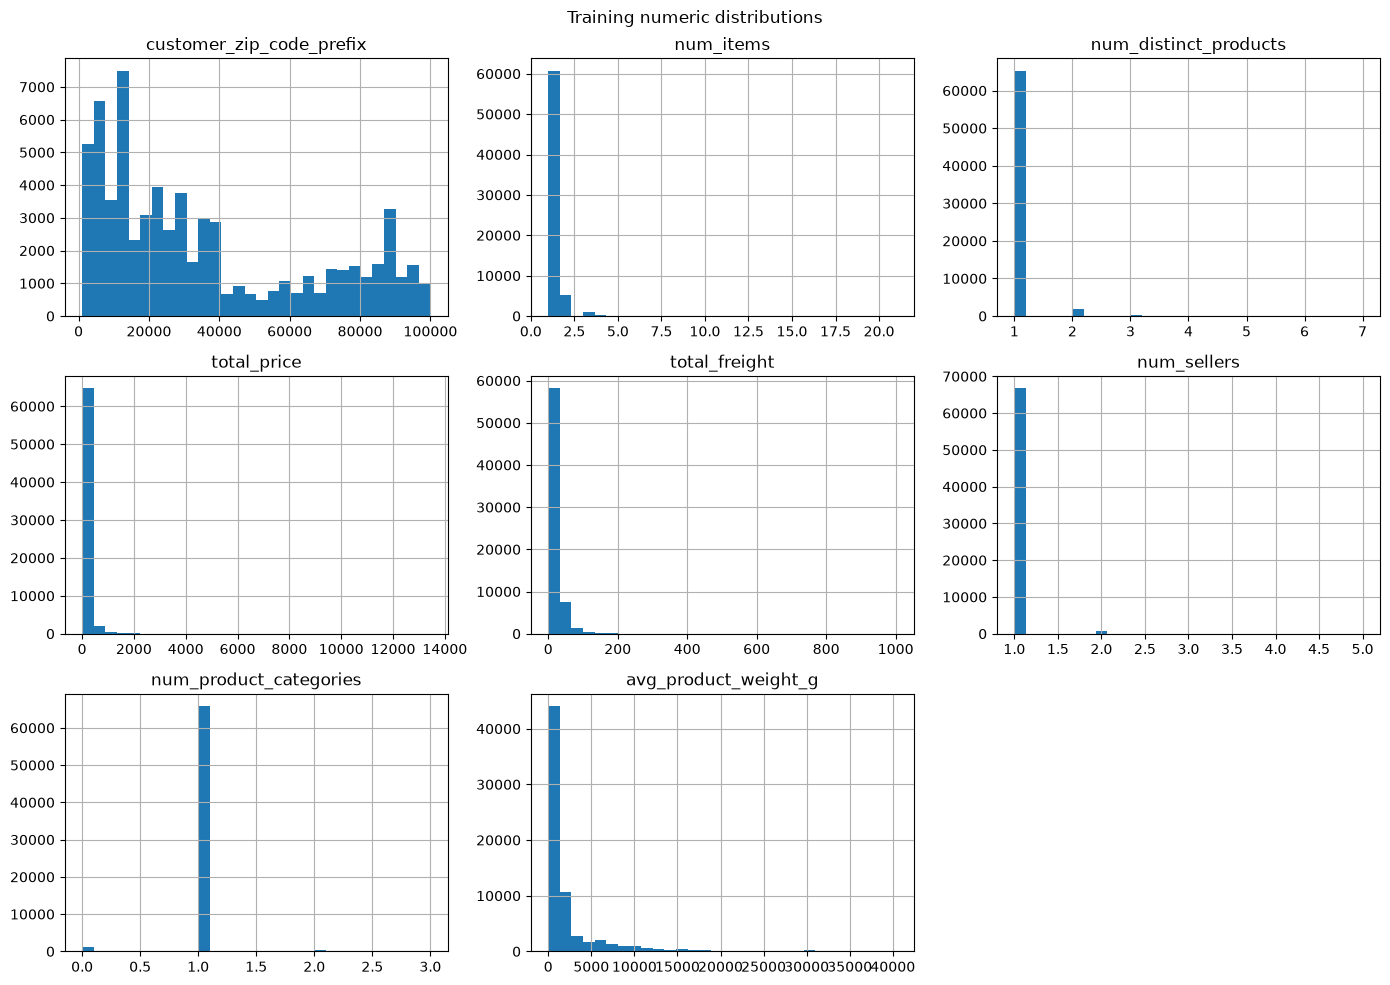

In [3]:
numeric_columns = train.select_dtypes(include=np.number).columns.tolist()
num_stats = train[numeric_columns].describe().T
num_stats["skew"] = train[numeric_columns].skew(numeric_only=True)
display(num_stats)

if numeric_columns:
    plot_cols = [c for c in numeric_columns if c != "is_late"][:8]
    if plot_cols:
        train[plot_cols].hist(figsize=(14, 10), bins=30)
        plt.suptitle("Training numeric distributions")
        plt.tight_layout()
        plt.savefig(charts_dir / "numeric_distributions.png", dpi=150)
        plt.show()
        plt.close()


## 3. Categorical cardinality and relationship with the target


C:\Users\HP\AppData\Local\Temp\ipykernel_9204\2221938400.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = train.select_dtypes(include=["object", "category"]).columns.tolist()


,n_unique,missing
order_id,67529,0
customer_id,67529,0
customer_unique_id,65397,0
customer_city,3747,0
customer_state,27,0
order_status,1,0


,count,mean,late_percentage
customer_state,,,
AL,298,0.278523,27.852349
MA,548,0.215328,21.532847
CE,948,0.182489,18.248945
RR,29,0.172414,17.241379
SE,246,0.170732,17.073171
PI,348,0.166667,16.666667
RJ,8965,0.165867,16.586726
BA,2307,0.149978,14.997833
PA,718,0.133705,13.370474


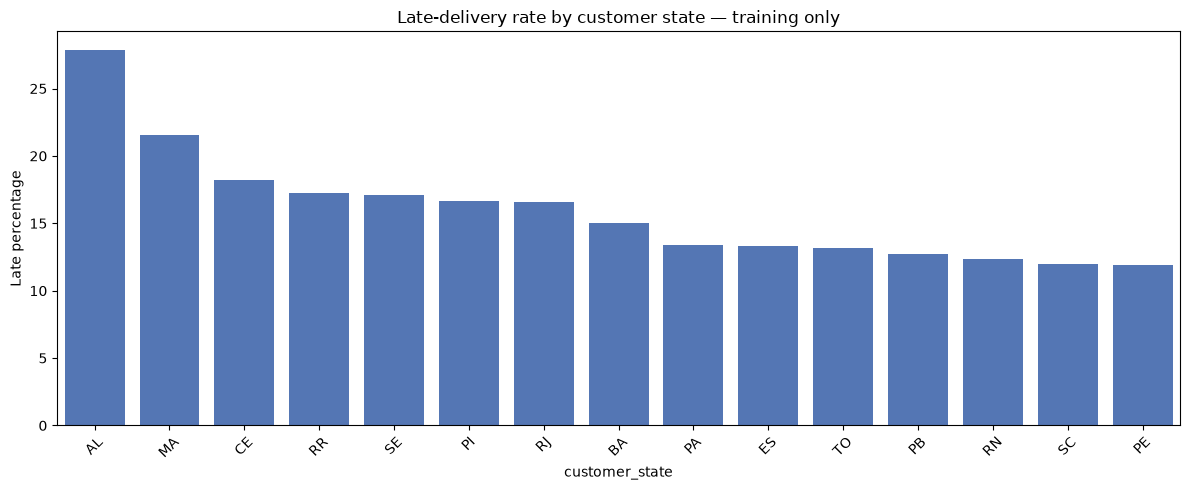

In [4]:
categorical_columns = train.select_dtypes(include=["object", "category"]).columns.tolist()
cat_summary = pd.DataFrame({"n_unique": train[categorical_columns].nunique(dropna=True), "missing": train[categorical_columns].isna().sum()}).sort_values("n_unique", ascending=False)
display(cat_summary)

state_rates = train.groupby("customer_state", dropna=False)["is_late"].agg(["count", "mean"]).sort_values("mean", ascending=False)
state_rates["late_percentage"] = 100 * state_rates["mean"]
display(state_rates.head(15))

if "customer_state" in train.columns:
    plt.figure(figsize=(12, 5))
    order = state_rates.head(15).index
    sns.barplot(data=state_rates.loc[order].reset_index(), x="customer_state", y="late_percentage", color="#4472C4")
    plt.xticks(rotation=45)
    plt.ylabel("Late percentage")
    plt.title("Late-delivery rate by customer state — training only")
    plt.tight_layout()
    plt.savefig(charts_dir / "late_rate_by_customer_state.png", dpi=150)
    plt.show()
    plt.close()


## 4. Date and delivery-duration analysis


In [5]:
train["purchase_month"] = train["order_purchase_timestamp"].dt.month
train["purchase_weekday"] = train["order_purchase_timestamp"].dt.dayofweek
train["approval_hours"] = (train["order_approved_at"] - train["order_purchase_timestamp"]).dt.total_seconds() / 3600
train["estimated_window_days"] = (train["order_estimated_delivery_date"] - train["order_purchase_timestamp"]).dt.total_seconds() / 86400

date_summary = train.groupby("purchase_month", dropna=False)["is_late"].agg(["count", "mean"]).reset_index()
date_summary["late_percentage"] = 100 * date_summary["mean"]
display(date_summary)


,purchase_month,count,mean,late_percentage
0,1,7819,0.062284,6.228418
1,2,8208,0.134137,13.413743
2,3,9549,0.171536,17.153629
3,4,5512,0.070210,7.021045
4,5,3545,0.036107,3.610719
5,6,3135,0.038596,3.859649
6,7,3872,0.034349,3.434917
7,8,4193,0.033150,3.315049
8,9,4151,0.052277,5.227656
9,10,4743,0.050601,5.060089


## 5. Findings summary

The findings below are deliberately concise and will be used by Notebook 5. Post-outcome columns such as actual delivery dates and review scores are excluded from prediction features to avoid leakage.


In [6]:
findings = f"""# Notebook 4 Findings

- The analysis used the training split only ({len(train):,} rows).
- The target late-delivery rate in training is {100 * train.is_late.mean():.2f}%.
- High-cardinality identifiers should not be used directly as model features.
- Missingness must be handled inside a fitted training-only preprocessing pipeline.
- Date components and pre-delivery durations are candidates for feature engineering.
- Customer and seller geography are candidate categorical features.
- Actual delivery dates and post-delivery reviews are analysis/label-support fields, not prediction features.
"""
(ARTIFACTS_DIR / "reports" / "04_findings.md").write_text(findings, encoding="utf-8")
print(findings)
print(f"Saved charts to {charts_dir}")


# Notebook 4 Findings

- The analysis used the training split only (67,529 rows).
- The target late-delivery rate in training is 9.03%.
- High-cardinality identifiers should not be used directly as model features.
- Missingness must be handled inside a fitted training-only preprocessing pipeline.
- Date components and pre-delivery durations are candidates for feature engineering.
- Customer and seller geography are candidate categorical features.
- Actual delivery dates and post-delivery reviews are analysis/label-support fields, not prediction features.

Saved charts to C:\Users\HP\Desktop\MLOps\Task2\artifacts\charts


In [7]:
assert (ARTIFACTS_DIR / "reports" / "04_findings.md").exists()
assert any(charts_dir.glob("*.png"))
print("ALL NOTEBOOK 4 CHECKS PASSED")


ALL NOTEBOOK 4 CHECKS PASSED
